# ME282 Computational Fluid Dynamics: Assignment 4

The assignment has three parts: establish the fourth-order accuracy of a nine-point Poisson scheme; solve a manufactured modified Helmholtz problem and compare Gauss-Seidel with conjugate gradients; and solve a manufactured Neumann Poisson problem. The mathematical statements and parameter studies are reproduced here in concise form.

The discretizations are on a uniform square grid with $N$ intervals in each direction, $h=1/N$, and interior indices $i,j=1,\ldots,N-1$. Arrays use row-major layout: the first axis represents $y$ and the second represents $x$.

## 1. Nine-point Poisson stencil

The scheme combines the four diagonal and four axial neighbors:

$$\frac{\frac16\sum_{\rm diag}u+\frac23\sum_{\rm axial}u-\frac{10}{3}u_{ij}}{h^2}
=\frac{\sum_{\rm axial}f+8f_{ij}}{12}.$$

Taylor expansion gives the left side as $\nabla^2u+\frac{h^2}{12}\nabla^4u+O(h^4)$ and the right side as $f+\frac{h^2}{12}\nabla^2f+O(h^4)$. Since $\nabla^2u=f$ implies $\nabla^4u=\nabla^2f$, the leading $O(h^2)$ terms agree, leaving a fourth-order truncation error for a sufficiently smooth solution.

## 2. Modified Helmholtz problem

Solve

$$\nabla^2u-2u=-(k_x^2\pi^2+k_y^2\pi^2+2)\sin(k_x\pi x)\sin(k_y\pi y),$$

with zero Dirichlet data. The exact solution is the corresponding product of sines. The standard five-point scheme yields diagonal $-(4+2h^2)$ and unit neighbor coefficients after scaling by $h^2$. The requested error study uses $k_x=k_y=2$ and $N=25,50,100,200,400$; the requested iteration study uses $N=200$ and $k=1,5,10,20,50$.

The conjugate-gradient method is applied to the negative-definite matrix; multiplying the system by $-1$ gives the equivalent positive-definite system. The simultaneous split update found in one listing is retained separately and is identified as Jacobi-style rather than Gauss-Seidel. The lexicographic in-place Gauss-Seidel loop from the accompanying program is also implemented. For the larger parameter study, red-black ordering keeps the point Gauss-Seidel iteration practical in Python; this changes update ordering, not the underlying method.

## 3. Neumann Poisson problem

Solve $\nabla^2u=-8\pi^2\cos(2\pi x)\cos(2\pi y)$ with zero normal derivative and the gauge $u(1/2,1/2)=0$. The exact solution is $\cos(2\pi x)\cos(2\pi y)-1$.

**Source-versus-statement discrepancy:** the recorded implementation uses a degree-adjusted boundary stencil rather than clearly applying the stated one-sided first-derivative approximation. It also pins four neighboring nodes when $N$ is odd, rather than one value at the exact center. Its gauge replaces selected matrix rows but leaves the corresponding columns coupled, making the matrix nonsymmetric even though conjugate gradients assumes symmetry. These operations are preserved and their error trend is reported; do not treat that trend as verification of the stated method.

## Runtime

Python 3, NumPy, and Matplotlib are sufficient. Iteration caps and explicit breakdown checks make solver failure visible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def grid_coordinates(interval_count):
    """Return the interior nodes used by the finite-difference grids."""
    return np.arange(1, interval_count) / interval_count


def apply_dirichlet_helmholtz(values, interval_count):
    """Apply h^2 times the five-point Laplacian minus 2 h^2 I."""
    step = 1.0 / interval_count
    result = -(4.0 + 2.0 * step**2) * values.copy()
    result[:, :-1] += values[:, 1:]
    result[:, 1:] += values[:, :-1]
    result[:-1, :] += values[1:, :]
    result[1:, :] += values[:-1, :]
    return result


def conjugate_gradient(
    operator, right_hand_side, initial, tolerance, max_iterations
):
    """Apply the conjugate-gradient recurrence with explicit breakdown guards."""
    solution = initial.astype(float, copy=True)
    residual = right_hand_side - operator(solution)
    direction = residual.copy()
    residual_squared = np.vdot(residual, residual)
    residual_norm = np.sqrt(residual_squared)
    history = [residual_norm / np.sqrt(residual.size)]
    if residual_norm < tolerance:
        return solution, 0, residual_norm, True, history

    for iteration in range(1, max_iterations + 1):
        operator_direction = operator(direction)
        denominator = np.vdot(direction, operator_direction)
        if not np.isfinite(denominator) or abs(denominator) < 1e-30:
            raise RuntimeError("Conjugate-gradient denominator broke down.")
        step_length = residual_squared / denominator
        solution += step_length * direction
        residual -= step_length * operator_direction
        next_residual_squared = np.vdot(residual, residual)
        residual_norm = np.sqrt(next_residual_squared)
        history.append(residual_norm / np.sqrt(residual.size))
        if residual_norm < tolerance:
            return solution, iteration, residual_norm, True, history

        direction = residual + (
            next_residual_squared / residual_squared
        ) * direction
        residual_squared = next_residual_squared

    return solution, max_iterations, residual_norm, False, history


def helmholtz_data(interval_count, wave_x, wave_y):
    coordinates = grid_coordinates(interval_count)
    x_grid, y_grid = np.meshgrid(coordinates, coordinates)
    exact = np.sin(wave_x * np.pi * x_grid) * np.sin(
        wave_y * np.pi * y_grid
    )
    eigenvalue = wave_x**2 * np.pi**2 + wave_y**2 * np.pi**2 + 2.0
    right_hand_side = -eigenvalue * exact / interval_count**2
    return x_grid, y_grid, exact, right_hand_side


def solve_helmholtz_cg(
    interval_count=50,
    wave_x=2.0,
    wave_y=2.0,
    initial_value=1.0,
    tolerance=1e-12,
):
    x_grid, y_grid, exact, right_hand_side = helmholtz_data(
        interval_count, wave_x, wave_y
    )
    solution, iteration_count, residual_norm, converged, history = conjugate_gradient(
        lambda values: apply_dirichlet_helmholtz(values, interval_count),
        right_hand_side,
        np.full_like(right_hand_side, initial_value),
        tolerance=tolerance,
        max_iterations=10 * right_hand_side.size,
    )
    if not converged:
        raise RuntimeError(
            f"Helmholtz CG did not converge; residual={residual_norm:.3e}"
        )
    return x_grid, y_grid, solution, exact, iteration_count, residual_norm, history


def solve_helmholtz_simultaneous(interval_count=50, wave_x=2.0, wave_y=2.0):
    """Reproduce the recorded split update (a simultaneous/Jacobi update)."""
    _, _, exact, right_hand_side = helmholtz_data(
        interval_count, wave_x, wave_y
    )
    diagonal = -(4.0 + 2.0 / interval_count**2)
    solution = right_hand_side / diagonal
    previous = np.zeros_like(solution)
    tolerance = 1e-12

    for iteration in range(1, 1_000_001):
        if np.linalg.norm(solution - previous) < tolerance:
            break
        previous = solution.copy()
        neighbor_sum = np.zeros_like(solution)
        neighbor_sum[:, :-1] += previous[:, 1:]
        neighbor_sum[:, 1:] += previous[:, :-1]
        neighbor_sum[:-1, :] += previous[1:, :]
        neighbor_sum[1:, :] += previous[:-1, :]
        solution = (right_hand_side - neighbor_sum) / diagonal
    else:
        raise RuntimeError("Helmholtz split iteration did not converge.")

    return solution, exact, iteration, np.linalg.norm(solution - previous)


def solve_helmholtz_gauss_seidel(
    interval_count=40, wave_x=2.0, wave_y=2.0, tolerance=1e-12
):
    """Lexicographic in-place point Gauss-Seidel for a manageable grid."""
    _, _, exact, right_hand_side = helmholtz_data(
        interval_count, wave_x, wave_y
    )
    solution = np.zeros((interval_count + 1, interval_count + 1))
    diagonal = -(4.0 + 2.0 / interval_count**2)
    for iteration in range(1, 200_001):
        squared_update = 0.0
        for i in range(1, interval_count):
            for j in range(1, interval_count):
                old_value = solution[i, j]
                neighbors = (
                    solution[i - 1, j]
                    + solution[i + 1, j]
                    + solution[i, j - 1]
                    + solution[i, j + 1]
                )
                solution[i, j] = (
                    right_hand_side[i - 1, j - 1] - neighbors
                ) / diagonal
                squared_update += (solution[i, j] - old_value) ** 2
        update_rms = np.sqrt(
            squared_update / ((interval_count - 1) ** 2)
        )
        if update_rms < tolerance:
            return solution[1:-1, 1:-1], exact, iteration, update_rms
    raise RuntimeError("Lexicographic Gauss-Seidel did not converge.")


def solve_helmholtz_red_black(
    interval_count, wave_number, max_iterations=80_000, log_every=100
):
    """Red-black point Gauss-Seidel with RMS update stopping and residual log."""
    _, _, exact, right_hand_side = helmholtz_data(
        interval_count, wave_number, wave_number
    )
    solution = np.zeros((interval_count + 1, interval_count + 1))
    interior = solution[1:-1, 1:-1]
    row_indices, column_indices = np.indices(interior.shape)
    colors = ((row_indices + column_indices) % 2 == 0,
              (row_indices + column_indices) % 2 == 1)
    diagonal = -(4.0 + 2.0 / interval_count**2)
    history = []
    converged = False

    for iteration in range(1, max_iterations + 1):
        squared_update = 0.0
        for color in colors:
            old_values = interior[color].copy()
            neighbor_sum = (
                solution[2:, 1:-1]
                + solution[:-2, 1:-1]
                + solution[1:-1, 2:]
                + solution[1:-1, :-2]
            )
            updated_values = (right_hand_side - neighbor_sum) / diagonal
            changes = updated_values[color] - old_values
            squared_update += np.vdot(changes, changes)
            interior[color] = updated_values[color]

        update_rms = np.sqrt(
            squared_update / ((interval_count - 1) ** 2)
        )
        if iteration == 1 or iteration % log_every == 0:
            residual = (
                diagonal * interior
                + solution[2:, 1:-1]
                + solution[:-2, 1:-1]
                + solution[1:-1, 2:]
                + solution[1:-1, :-2]
                - right_hand_side
            )
            history.append(
                (iteration, np.sqrt(np.mean(residual**2)))
            )
        if update_rms < 1e-12:
            converged = True
            break

    if not history or history[-1][0] != iteration:
        residual = (
            diagonal * interior
            + solution[2:, 1:-1]
            + solution[:-2, 1:-1]
            + solution[1:-1, 2:]
            + solution[1:-1, :-2]
            - right_hand_side
        )
        history.append((iteration, np.sqrt(np.mean(residual**2))))

    return solution, exact, iteration, update_rms, history, converged


def neumann_pin_indices(interval_count):
    """Return flattened gauge indices used in the Neumann example."""
    interior_width = interval_count - 1
    if interval_count % 2 == 0:
        return [((interior_width**2) - 1) // 2]
    return [
        interior_width * (interval_count - 2) // 2 - 1,
        interior_width * (interval_count - 2) // 2,
        interior_width * interval_count // 2 - 1,
        interior_width * interval_count // 2,
    ]


def apply_neumann_laplacian(values, interval_count, pinned_indices):
    """Apply the archived degree-adjusted boundary stencil and gauge rows."""
    diagonal = -4.0 * np.ones_like(values)
    diagonal[0, :] = -3.0
    diagonal[-1, :] = -3.0
    diagonal[:, 0] = -3.0
    diagonal[:, -1] = -3.0
    diagonal[0, 0] = diagonal[0, -1] = -2.0
    diagonal[-1, 0] = diagonal[-1, -1] = -2.0

    result = diagonal * values
    result[:, :-1] += values[:, 1:]
    result[:, 1:] += values[:, :-1]
    result[:-1, :] += values[1:, :]
    result[1:, :] += values[:-1, :]
    flat_result = result.ravel()
    flat_values = values.ravel()
    flat_result[pinned_indices] = flat_values[pinned_indices]
    return result


def solve_neumann_poisson(interval_count=25):
    coordinates = grid_coordinates(interval_count)
    x_grid, y_grid = np.meshgrid(coordinates, coordinates)
    exact = np.cos(2.0 * np.pi * x_grid) * np.cos(
        2.0 * np.pi * y_grid
    ) - 1.0
    right_hand_side = (
        -8.0
        * np.pi**2
        * np.cos(2.0 * np.pi * x_grid)
        * np.cos(2.0 * np.pi * y_grid)
        / interval_count**2
    )
    pinned_indices = neumann_pin_indices(interval_count)
    right_hand_side.ravel()[pinned_indices] = 0.0
    operator = lambda values: apply_neumann_laplacian(
        values, interval_count, pinned_indices
    )
    solution, iteration_count, residual_norm, converged, _ = conjugate_gradient(
        operator,
        right_hand_side,
        np.zeros_like(right_hand_side),
        tolerance=1e-12,
        max_iterations=10 * right_hand_side.size,
    )
    if not converged:
        raise RuntimeError(
            f"Neumann CG did not converge; residual={residual_norm:.3e}"
        )
    rms_error = np.sqrt(np.mean((solution - exact) ** 2))
    maximum_error = np.max(np.abs(solution - exact))
    return (
        x_grid,
        y_grid,
        solution,
        exact,
        pinned_indices,
        iteration_count,
        residual_norm,
        rms_error,
        maximum_error,
    )


## Modified Helmholtz example

Modified Helmholtz Dirichlet test, N=50, kx=ky=2
CG iterations = 126; residual norm = 5.422e-13
archived split-update iterations = 3209; last update norm = 9.954e-13
lexicographic Gauss-Seidel check, N=40: iterations=2335; last update RMS=9.985e-13; max difference from CG discrete solution=2.852e-10
RMS error = 6.553110266e-04
maximum error = 1.279345636e-03
maximum difference between solvers = 4.872e-12


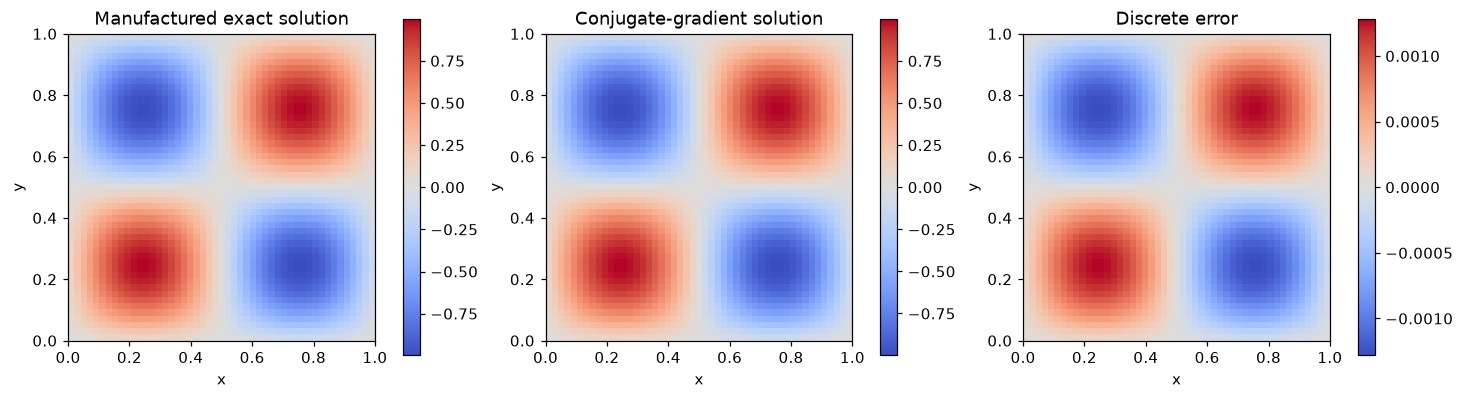

In [2]:
# Reproduce the N=50, kx=ky=2 listings.
interval_count = 50
x_grid, y_grid, cg_solution, exact_solution, cg_iterations, cg_residual, _ = (
    solve_helmholtz_cg(interval_count)
)
iterative_solution, _, iterative_count, final_update_norm = (
    solve_helmholtz_simultaneous(interval_count)
)
gs_solution, gs_exact, gs_count, gs_update_norm = solve_helmholtz_gauss_seidel(
    interval_count=40
)
_, _, gs_cg_solution, _, _, _, _ = solve_helmholtz_cg(
    interval_count=40, initial_value=0.0
)
rms_error = np.sqrt(np.mean((cg_solution - exact_solution) ** 2))
maximum_error = np.max(np.abs(cg_solution - exact_solution))
solver_difference = np.max(np.abs(cg_solution - iterative_solution))

print("Modified Helmholtz Dirichlet test, N=50, kx=ky=2")
print(f"CG iterations = {cg_iterations}; residual norm = {cg_residual:.3e}")
print(
    f"archived split-update iterations = {iterative_count}; "
    f"last update norm = {final_update_norm:.3e}"
)
print(
    f"lexicographic Gauss-Seidel check, N=40: iterations={gs_count}; "
    f"last update RMS={gs_update_norm:.3e}; "
    f"max difference from CG discrete solution="
    f"{np.max(np.abs(gs_solution - gs_cg_solution)):.3e}"
)
print(f"RMS error = {rms_error:.9e}")
print(f"maximum error = {maximum_error:.9e}")
print(f"maximum difference between solvers = {solver_difference:.3e}")

figure, axes = plt.subplots(1, 3, figsize=(13.2, 4.0), constrained_layout=True)
panels = (
    (exact_solution, "Manufactured exact solution"),
    (cg_solution, "Conjugate-gradient solution"),
    (cg_solution - exact_solution, "Discrete error"),
)
for axis, (field, title) in zip(axes, panels):
    image = axis.imshow(
        field,
        origin="lower",
        extent=(0, 1, 0, 1),
        aspect="equal",
        cmap="coolwarm",
    )
    axis.set(title=title, xlabel="x", ylabel="y")
    figure.colorbar(image, ax=axis, shrink=0.78)
plt.show()


The simultaneous update and true Gauss-Seidel loop approach the same discrete solution as conjugate gradients. The simultaneous update retains its label from the earlier listing but is not in-place Gauss-Seidel.

### L2 error and grid-refinement study

Modified Helmholtz L2 error (full grid, kx=ky=2)
 N       L2 error       CG iterations
 25    2.47564e-03      1
 50    6.29613e-04      1
100    1.58871e-04      1
200    3.99098e-05      1
400    1.00020e-05      1
fitted convergence order = 1.9882


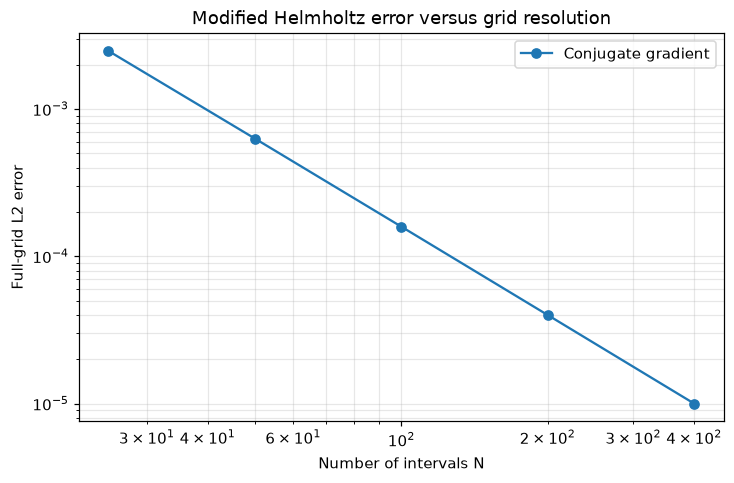

In [3]:
# Official resolution study for kx=ky=2.
interval_counts = np.array([25, 50, 100, 200, 400])
helmholtz_errors = []
helmholtz_iterations = []

for interval_count in interval_counts:
    interior_size = interval_count - 1
    _, _, numerical_interior, _, iteration_count, _, _ = solve_helmholtz_cg(
        interval_count,
        wave_x=2.0,
        wave_y=2.0,
        initial_value=0.0,
        tolerance=1e-12 * np.sqrt(interior_size**2),
    )
    coordinates = np.arange(interval_count + 1) / interval_count
    x_grid, y_grid = np.meshgrid(coordinates, coordinates)
    exact_full = np.sin(2.0 * np.pi * x_grid) * np.sin(
        2.0 * np.pi * y_grid
    )
    numerical_full = np.zeros_like(exact_full)
    numerical_full[1:-1, 1:-1] = numerical_interior
    l2_error = np.sqrt(
        np.sum((numerical_full - exact_full) ** 2)
        / (interval_count + 1) ** 2
    )
    helmholtz_errors.append(l2_error)
    helmholtz_iterations.append(iteration_count)

helmholtz_errors = np.asarray(helmholtz_errors)
convergence_order = np.polyfit(
    np.log(interval_counts), np.log(helmholtz_errors), 1
)[0] * -1.0
print("Modified Helmholtz L2 error (full grid, kx=ky=2)")
print(" N       L2 error       CG iterations")
for count, error, iteration_count in zip(
    interval_counts, helmholtz_errors, helmholtz_iterations
):
    print(f"{count:3d}   {error:12.5e}   {iteration_count:4d}")
print(f"fitted convergence order = {convergence_order:.4f}")

figure, axes = plt.subplots(figsize=(6.8, 4.5))
axes.loglog(interval_counts, helmholtz_errors, "o-", label="Conjugate gradient")
axes.set(
    xlabel="Number of intervals N",
    ylabel="Full-grid L2 error",
    title="Modified Helmholtz error versus grid resolution",
)
axes.grid(True, which="both", alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()


Because the right-hand side is a single discrete sine mode, a zero-start conjugate-gradient solve reaches the discrete solution in one iteration up to rounding. The continuous-solution error still decreases at the expected second-order rate as the grid is refined.

### Residual histories versus wavenumber

N=200 iteration study; CG residual is RMS, GS stopping value is RMS update
 k    CG iterations     GS sweeps    GS update RMS    converged
 1          1           68933       9.999e-13      True
 5          1            3527       9.979e-13      True
10          1             939       9.787e-13      True
20          1             247       9.350e-13      True
50          1              40       5.889e-13      True


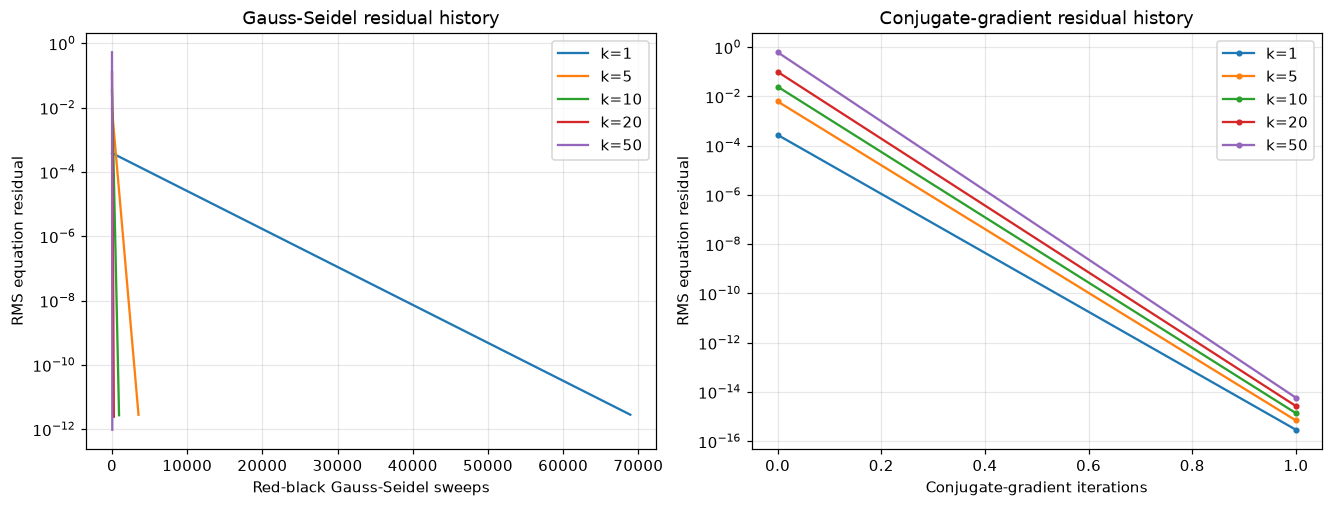

In [4]:
# Official iteration study: N=200 and kx=ky=k.
interval_count = 200
wave_numbers = (1, 5, 10, 20, 50)
gauss_seidel_histories = {}
cg_histories = {}
gauss_seidel_status = {}

for wave_number in wave_numbers:
    _, _, _, right_hand_side = helmholtz_data(
        interval_count, wave_number, wave_number
    )
    cg_size = right_hand_side.size
    _, cg_iterations, _, _, cg_history = conjugate_gradient(
        lambda values: apply_dirichlet_helmholtz(values, interval_count),
        right_hand_side,
        np.zeros_like(right_hand_side),
        tolerance=1e-12 * np.sqrt(cg_size),
        max_iterations=10 * cg_size,
    )
    cg_histories[wave_number] = (
        np.arange(len(cg_history)),
        np.asarray(cg_history),
    )

    _, _, iterations, update_rms, residual_history, converged = (
        solve_helmholtz_red_black(
            interval_count, wave_number, max_iterations=100_000
        )
    )
    gauss_seidel_histories[wave_number] = (
        np.asarray([point[0] for point in residual_history]),
        np.asarray([point[1] for point in residual_history]),
    )
    gauss_seidel_status[wave_number] = (
        iterations,
        update_rms,
        converged,
    )

print("N=200 iteration study; CG residual is RMS, GS stopping value is RMS update")
print(" k    CG iterations     GS sweeps    GS update RMS    converged")
for wave_number in wave_numbers:
    iterations, update_rms, converged = gauss_seidel_status[wave_number]
    print(
        f"{wave_number:2d}       {len(cg_histories[wave_number][0])-1:4d}"
        f"          {iterations:6d}      {update_rms:10.3e}      {converged}"
    )

figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.5), constrained_layout=True)
for wave_number in wave_numbers:
    iterations, residuals = gauss_seidel_histories[wave_number]
    axes[0].semilogy(
        iterations, residuals, label=f"k={wave_number}"
    )
    iterations, residuals = cg_histories[wave_number]
    axes[1].semilogy(
        iterations, residuals, "o-", markersize=3, label=f"k={wave_number}"
    )
axes[0].set(
    xlabel="Red-black Gauss-Seidel sweeps",
    ylabel="RMS equation residual",
    title="Gauss-Seidel residual history",
)
axes[1].set(
    xlabel="Conjugate-gradient iterations",
    ylabel="RMS equation residual",
    title="Conjugate-gradient residual history",
)
for axis in axes:
    axis.grid(True, which="both", alpha=0.3)
    axis.legend()
plt.show()


Conjugate gradients converges in approximately one iteration for these single-mode manufactured right-hand sides, so the plotted traces nearly coincide. Gauss-Seidel damps large wavenumbers more quickly; the low-wavenumber case converges much more slowly. Red-black ordering is used for this study, and its RMS equation residual is plotted while the stopping test follows the assignment's RMS change between iterates.

## Neumann Poisson results

Neumann Poisson test, N=25
CG iterations = 57
residual norm = 5.909e-13
RMS error = 6.261432680e-02
maximum error = 1.493380817e-01
pinned flattened indices = [275, 276, 299, 300]


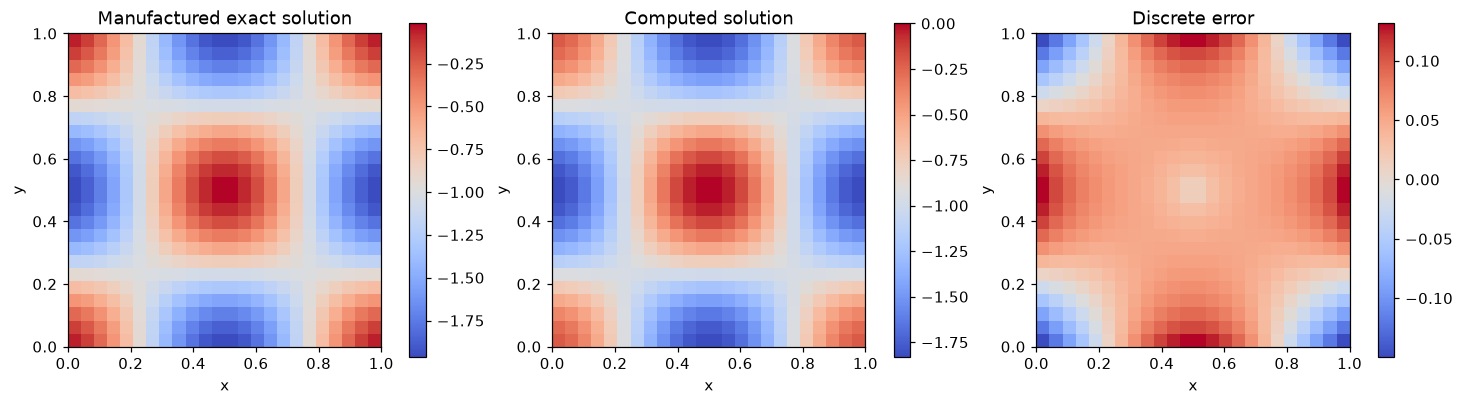

In [5]:
(
    x_grid,
    y_grid,
    neumann_solution,
    neumann_exact,
    pinned_indices,
    neumann_iterations,
    neumann_residual,
    neumann_rms_error,
    neumann_max_error,
) = solve_neumann_poisson()

print("Neumann Poisson test, N=25")
print(f"CG iterations = {neumann_iterations}")
print(f"residual norm = {neumann_residual:.3e}")
print(f"RMS error = {neumann_rms_error:.9e}")
print(f"maximum error = {neumann_max_error:.9e}")
print(f"pinned flattened indices = {pinned_indices}")

figure, axes = plt.subplots(1, 3, figsize=(13.2, 4.0), constrained_layout=True)
panels = (
    (neumann_exact, "Manufactured exact solution"),
    (neumann_solution, "Computed solution"),
    (neumann_solution - neumann_exact, "Discrete error"),
)
for axis, (field, title) in zip(axes, panels):
    image = axis.imshow(
        field,
        origin="lower",
        extent=(0, 1, 0, 1),
        aspect="equal",
        cmap="coolwarm",
    )
    axis.set(title=title, xlabel="x", ylabel="y")
    figure.colorbar(image, ax=axis, shrink=0.78)
plt.show()


At $N=25$, four adjacent unknowns are pinned because the center is not a grid point. This is not equivalent to the stated single-point gauge, and the row-only replacement also violates matrix symmetry.

### Neumann error trend under the recorded implementation

Neumann test: interior RMS error using the recorded gauge rows
 N       RMS error       CG iterations
 24    7.35100e-02     57
 25    6.26143e-02     57
 32    4.94428e-02     80
 40    3.72521e-02    102
 48    3.00274e-02    123
 64    2.18952e-02    166
 80    1.74018e-02    208
fitted error order over these grids = 1.1640


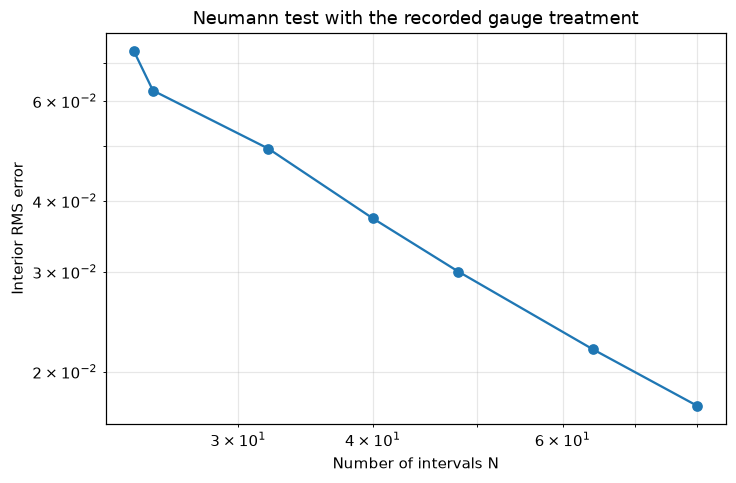

In [6]:
# The recorded gauge rows are applied unchanged at each resolution.
interval_counts = np.array([24, 25, 32, 40, 48, 64, 80])
neumann_errors = []
neumann_iterations = []
for interval_count in interval_counts:
    result = solve_neumann_poisson(interval_count)
    neumann_errors.append(result[7])
    neumann_iterations.append(result[5])

neumann_errors = np.asarray(neumann_errors)
neumann_order = -np.polyfit(
    np.log(interval_counts), np.log(neumann_errors), 1
)[0]
print("Neumann test: interior RMS error using the recorded gauge rows")
print(" N       RMS error       CG iterations")
for count, error, iterations in zip(
    interval_counts, neumann_errors, neumann_iterations
):
    print(f"{count:3d}   {error:12.5e}   {iterations:4d}")
print(f"fitted error order over these grids = {neumann_order:.4f}")

figure, axes = plt.subplots(figsize=(6.8, 4.5))
axes.loglog(interval_counts, neumann_errors, "o-")
axes.set(
    xlabel="Number of intervals N",
    ylabel="Interior RMS error",
    title="Neumann test with the recorded gauge treatment",
)
axes.grid(True, which="both", alpha=0.3)
figure.tight_layout()
plt.show()


The measured trend is not the expected second-order result for the assignment's stated boundary treatment. It diagnoses a discrepancy in the recovered implementation and gauge, not a verified failure of the stated finite-difference method.